# 10. Model Comparison and Final Conclusion

This notebook **does not retrain models**. It reads evaluation metrics and one-day-ahead forecasts saved by model notebooks 04–09.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

HERE = Path.cwd().resolve()
SEARCH_DIRS = [HERE, *HERE.parents]
PROJECT_ROOT = None

for folder in SEARCH_DIRS:
    looks_like_project = (
        (folder / "notebooks").is_dir()
        and ((folder / "data").is_dir() or (folder / "results").is_dir())
    ) or (
        (folder / "data").is_dir()
        and (folder / "results").is_dir()
    )
    if looks_like_project:
        PROJECT_ROOT = folder
        break

if PROJECT_ROOT is None:
    PROJECT_ROOT = HERE

RESULTS_DIR = PROJECT_ROOT / "results"
NEW_METRICS_FILE = RESULTS_DIR / "model_results.csv"
LEGACY_METRICS_FILE = RESULTS_DIR / "model_metrics.csv"
FUTURE_PREDICTIONS_FILE = RESULTS_DIR / "future_predictions.csv"

metrics = None
metrics_file = None
for candidate in [NEW_METRICS_FILE, LEGACY_METRICS_FILE]:
    if candidate.exists() and candidate.stat().st_size > 0:
        candidate_metrics = pd.read_csv(candidate)
        if not candidate_metrics.empty:
            metrics = candidate_metrics
            metrics_file = candidate
            break

if metrics is None:
    raise FileNotFoundError(
        "No model results were found. Expected a populated file at one of these paths:\n"
        f"- {NEW_METRICS_FILE}\n"
        f"- {LEGACY_METRICS_FILE}\n"
        "Run each updated model notebook through its final result-saving cell first."
    )

required = {"Model", "MAE", "RMSE"}
missing = required - set(metrics.columns)
if missing:
    raise ValueError(
        f"Missing required columns in {metrics_file}: {sorted(missing)}"
    )

if "MAPE_percent" not in metrics.columns and "MAPE" in metrics.columns:
    metrics = metrics.rename(columns={"MAPE": "MAPE_percent"})
if "Evaluation_Protocol" not in metrics.columns:
    metrics["Evaluation_Protocol"] = "Not recorded"
if "N_Evaluated" not in metrics.columns:
    metrics["N_Evaluated"] = np.nan

for col in ["MAE", "RMSE", "MAPE_percent", "N_Evaluated"]:
    if col in metrics.columns:
        metrics[col] = pd.to_numeric(metrics[col], errors="coerce")

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print(f"Project root: {PROJECT_ROOT}")
print(f"Metrics loaded from: {metrics_file}")
print(f"Models recorded: {len(metrics)}")
display(metrics.sort_values("MAE", na_position="last").reset_index(drop=True))


Project root: C:\Users\naras\OneDrive\Sem5\Y_TAI_Project\stock-price-forecasting
Metrics loaded from: C:\Users\naras\OneDrive\Sem5\Y_TAI_Project\stock-price-forecasting\results\model_results.csv
Models recorded: 11


,Model,Model_Family,MAE,RMSE,MAPE_percent,N_Evaluated,Evaluation_Protocol
0,Naive Baseline,Naive,9.510425,14.320585,1.185863,2890,full_series_next_day_baseline
1,Dynamic Regression AR(1),Dynamic Regression,13.324324,17.846003,0.974386,582,80/20 chronological holdout with rolling one-s...
2,SARIMA,SARIMA,13.352334,17.837061,0.975659,578,80/20 chronological holdout with rolling one-s...
3,Multiple Linear Regression,Dynamic Regression,14.698835,19.796700,1.075025,582,80/20 chronological holdout; rolling one-step ...
4,Linear Regression,Linear Regression,15.154165,20.354362,1.108179,578,80/20 chronological holdout
5,Dynamic Regression with Lagged Predictors,Dynamic Regression,15.302854,20.540908,1.119109,582,80/20 chronological holdout; lagged-predictor ...
6,"Dynamic Regression ARIMA(1,1,1)",Dynamic Regression,71.917982,94.984407,5.254405,582,80/20 chronological holdout with rolling one-s...
7,Holt Damped Trend,Exponential Smoothing,92.857684,111.486629,6.968476,610,80/20 chronological holdout; multi-step forecast
8,Simple Exponential Smoothing,Exponential Smoothing,92.857696,111.486644,6.968477,610,80/20 chronological holdout; multi-step forecast
9,ARIMA,ARIMA,92.973403,111.642487,6.978685,610,80/20 chronological holdout


## 1. Leaderboard

In [2]:
leaderboard = (
    metrics.sort_values(["MAE", "RMSE"], ascending=True, na_position="last")
    .reset_index(drop=True)
)
leaderboard.insert(0, "Rank", np.arange(1, len(leaderboard) + 1))
display(leaderboard)

leaderboard_path = RESULTS_DIR / "model_leaderboard.csv"
leaderboard.to_csv(leaderboard_path, index=False)
print(f"Saved leaderboard to: {leaderboard_path}")


,Rank,Model,Model_Family,MAE,RMSE,MAPE_percent,N_Evaluated,Evaluation_Protocol
0,1,Naive Baseline,Naive,9.510425,14.320585,1.185863,2890,full_series_next_day_baseline
1,2,Dynamic Regression AR(1),Dynamic Regression,13.324324,17.846003,0.974386,582,80/20 chronological holdout with rolling one-s...
2,3,SARIMA,SARIMA,13.352334,17.837061,0.975659,578,80/20 chronological holdout with rolling one-s...
3,4,Multiple Linear Regression,Dynamic Regression,14.698835,19.796700,1.075025,582,80/20 chronological holdout; rolling one-step ...
4,5,Linear Regression,Linear Regression,15.154165,20.354362,1.108179,578,80/20 chronological holdout
5,6,Dynamic Regression with Lagged Predictors,Dynamic Regression,15.302854,20.540908,1.119109,582,80/20 chronological holdout; lagged-predictor ...
6,7,"Dynamic Regression ARIMA(1,1,1)",Dynamic Regression,71.917982,94.984407,5.254405,582,80/20 chronological holdout with rolling one-s...
7,8,Holt Damped Trend,Exponential Smoothing,92.857684,111.486629,6.968476,610,80/20 chronological holdout; multi-step forecast
8,9,Simple Exponential Smoothing,Exponential Smoothing,92.857696,111.486644,6.968477,610,80/20 chronological holdout; multi-step forecast
9,10,ARIMA,ARIMA,92.973403,111.642487,6.978685,610,80/20 chronological holdout


Saved leaderboard to: C:\Users\naras\OneDrive\Sem5\Y_TAI_Project\stock-price-forecasting\results\model_leaderboard.csv


## 2. Compare error metrics

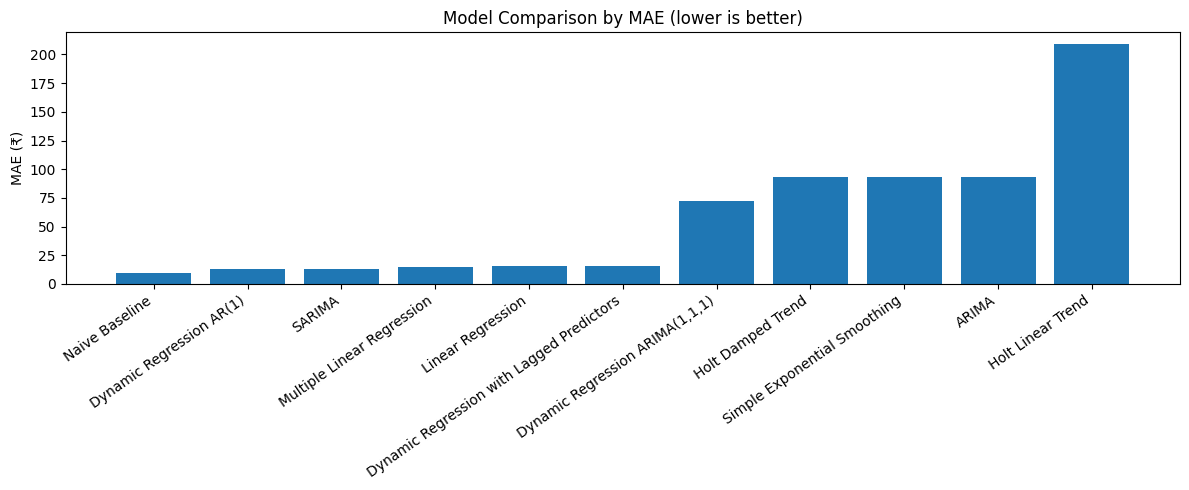

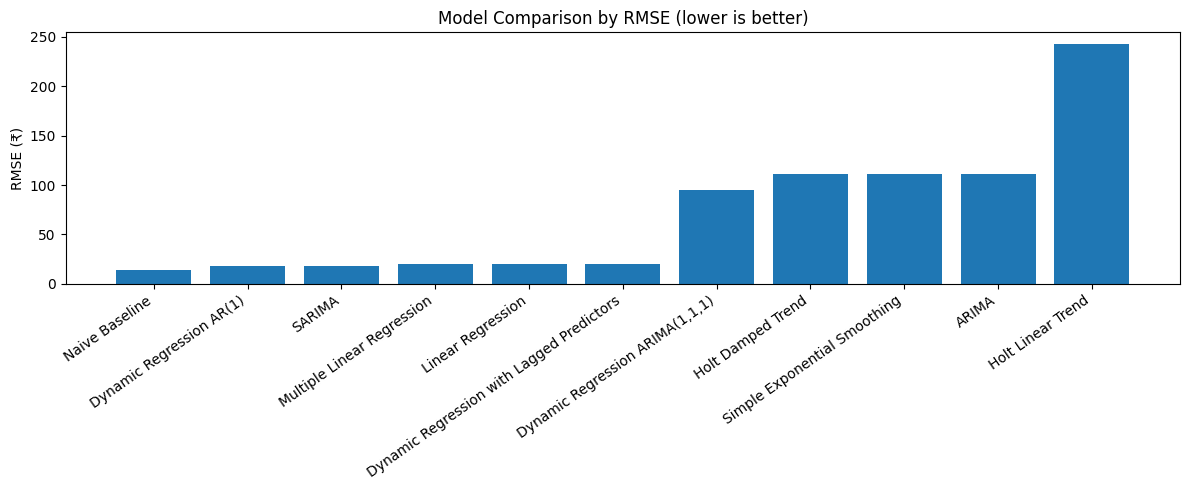

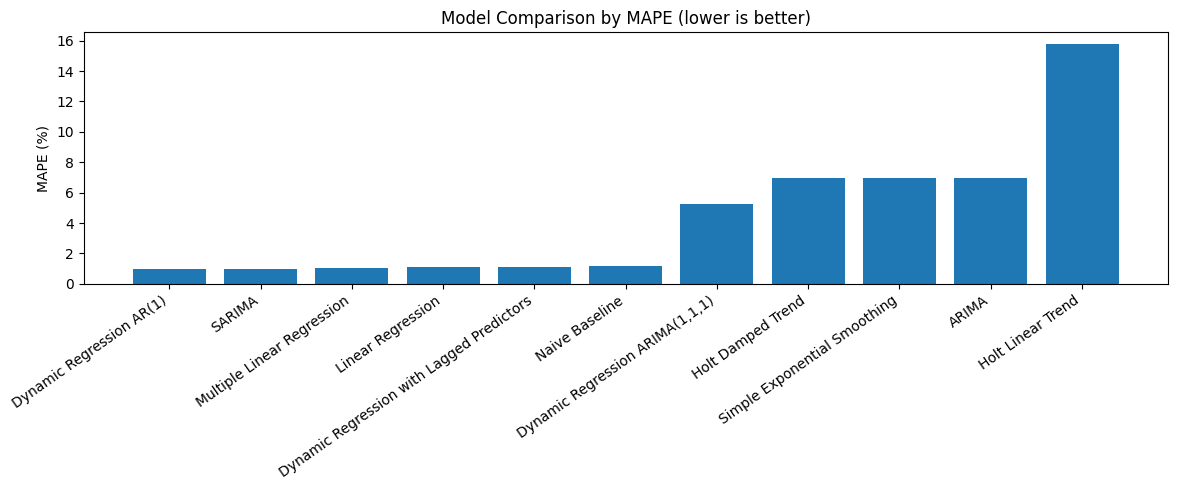

In [3]:
plot_data = metrics.dropna(subset=["MAE"]).sort_values("MAE")

if plot_data.empty:
    print("No valid MAE values are available to plot.")
else:
    plt.figure(figsize=(12, 5))
    plt.bar(plot_data["Model"], plot_data["MAE"])
    plt.title("Model Comparison by MAE (lower is better)")
    plt.ylabel("MAE (₹)")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(12, 5))
    plt.bar(plot_data["Model"], plot_data["RMSE"])
    plt.title("Model Comparison by RMSE (lower is better)")
    plt.ylabel("RMSE (₹)")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

if "MAPE_percent" in metrics.columns:
    mape_data = metrics.dropna(subset=["MAPE_percent"]).sort_values("MAPE_percent")
    if not mape_data.empty:
        plt.figure(figsize=(12, 5))
        plt.bar(mape_data["Model"], mape_data["MAPE_percent"])
        plt.title("Model Comparison by MAPE (lower is better)")
        plt.ylabel("MAPE (%)")
        plt.xticks(rotation=35, ha="right")
        plt.tight_layout()
        plt.show()


## 3. Best model and its predictions

In [4]:
rankable = metrics.dropna(subset=["MAE"]).sort_values(
    ["MAE", "RMSE"], ascending=True
)
if rankable.empty:
    raise ValueError("No models have valid MAE values.")

winner = rankable.iloc[0]
mape_text = (
    f"- **MAPE:** {winner['MAPE_percent']:.2f}%\n"
    if "MAPE_percent" in winner.index and pd.notna(winner.get("MAPE_percent"))
    else ""
)
n_eval = winner.get("N_Evaluated", np.nan)
n_eval_text = int(n_eval) if pd.notna(n_eval) else "not recorded"

display(Markdown(
    f"## Best recorded evaluation: **{winner['Model']}**\n"
    f"- **MAE:** ₹{winner['MAE']:.2f}\n"
    f"- **RMSE:** ₹{winner['RMSE']:.2f}\n"
    + mape_text
    + f"- **Evaluated observations:** {n_eval_text}"
))

prediction_value = winner.get("Prediction_File", None)
if prediction_value is not None and pd.notna(prediction_value) and str(prediction_value).strip():
    prediction_file = Path(str(prediction_value))
    if not prediction_file.is_absolute():
        prediction_file = PROJECT_ROOT / prediction_file

    if prediction_file.exists():
        pred = pd.read_csv(prediction_file)
        if {"Actual", "Predicted"}.issubset(pred.columns):
            if "Date" in pred.columns:
                pred["Date"] = pd.to_datetime(pred["Date"], errors="coerce")
                pred = pred.sort_values("Date")
                x = pred["Date"]
            else:
                x = np.arange(len(pred))

            plt.figure(figsize=(13, 5))
            plt.plot(x, pred["Actual"], label="Actual", linewidth=2)
            plt.plot(x, pred["Predicted"], label="Predicted", linewidth=2)
            plt.title(f"Actual vs Predicted Close Price: {winner['Model']}")
            plt.xlabel("Date")
            plt.ylabel("Close Price (₹)")
            plt.legend()
            plt.tight_layout()
            plt.show()

            if "Residual" in pred.columns:
                plt.figure(figsize=(12, 4))
                plt.plot(x, pred["Residual"])
                plt.axhline(0, linestyle="--")
                plt.title(f"Residuals: {winner['Model']}")
                plt.xlabel("Date")
                plt.ylabel("Actual - Predicted (₹)")
                plt.tight_layout()
                plt.show()
        else:
            print(f"Prediction file lacks Actual/Predicted columns: {prediction_file}")
    else:
        print(f"Prediction file not found: {prediction_file}")
else:
    print(
        "Per-observation historical prediction files are not recorded in this results format. "
        "Metrics comparison will still work; future forecasts are shown in Section 4."
    )


## Best recorded evaluation: **Naive Baseline**
- **MAE:** ₹9.51
- **RMSE:** ₹14.32
- **MAPE:** 1.19%
- **Evaluated observations:** 2890

Per-observation historical prediction files are not recorded in this results format. Metrics comparison will still work; future forecasts are shown in Section 4.


## 4. Compare one-day-ahead forecasts

In [5]:
if FUTURE_PREDICTIONS_FILE.exists() and FUTURE_PREDICTIONS_FILE.stat().st_size > 0:
    future_predictions = pd.read_csv(FUTURE_PREDICTIONS_FILE)
    required_future = {"Model", "Date", "Predicted_Price"}
    missing_future = required_future - set(future_predictions.columns)

    if missing_future:
        print(
            "Future predictions file is missing required columns: "
            f"{sorted(missing_future)}"
        )
    elif future_predictions.empty:
        print("The future predictions file exists but contains no forecasts yet.")
    else:
        future_predictions["Date"] = pd.to_datetime(
            future_predictions["Date"], errors="coerce"
        )
        future_predictions["Predicted_Price"] = pd.to_numeric(
            future_predictions["Predicted_Price"], errors="coerce"
        )
        future_predictions = future_predictions.dropna(
            subset=["Date", "Predicted_Price"]
        ).sort_values(["Date", "Model"])

        display(future_predictions.reset_index(drop=True))

        future_comparison_path = RESULTS_DIR / "future_predictions_comparison.csv"
        future_predictions.to_csv(future_comparison_path, index=False)
        print(f"Saved future forecast comparison to: {future_comparison_path}")

        target_dates = future_predictions["Date"].dt.strftime("%Y-%m-%d").dropna().unique()
        if len(target_dates) == 1:
            print(f"All recorded forecasts target the same date: {target_dates[0]}")
            plot_future = future_predictions.sort_values("Predicted_Price")
            plt.figure(figsize=(12, 5))
            plt.bar(plot_future["Model"], plot_future["Predicted_Price"])
            plt.title(f"One-Day-Ahead Predicted Closing Prices ({target_dates[0]})")
            plt.ylabel("Predicted Close Price (₹)")
            plt.xticks(rotation=35, ha="right")
            plt.tight_layout()
            plt.show()
        elif len(target_dates) > 1:
            print(
                "WARNING: forecasts have different target dates: "
                + ", ".join(target_dates)
                + ". Do not compare these predictions as forecasts for the same day. "
                "Check that all model notebooks use the same forecast-date rule."
            )
else:
    print(
        f"No future forecast file found at {FUTURE_PREDICTIONS_FILE}. "
        "Run the final result-saving cell in each updated model notebook first."
    )

,Model,Date,Predicted_Price
0,ARIMA,2026-10-08,1207.699951
1,Holt Damped Trend,2026-10-08,1207.754523
2,Holt Linear Trend,2026-10-08,1208.088104
3,Linear Regression,2026-10-08,1216.842211
4,Naive Baseline,2026-10-08,1207.699951
5,SARIMA,2026-10-08,1207.699951
6,Simple Exponential Smoothing,2026-10-08,1207.754478
7,Dynamic Regression AR(1),2026-10-09,1177.604567
8,"Dynamic Regression ARIMA(1,1,1)",2026-10-09,1276.695417
9,Dynamic Regression with Lagged Predictors,2026-10-09,1194.575568


Saved future forecast comparison to: C:\Users\naras\OneDrive\Sem5\Y_TAI_Project\stock-price-forecasting\results\future_predictions_comparison.csv


## 5. Automatically generated conclusion


In [6]:
n_models = len(metrics)
conclusion = (
    f"Among the {n_models} model result(s) recorded in this experiment, "
    f"**{winner['Model']}** achieved the lowest recorded MAE at ₹{winner['MAE']:.2f}, "
    f"with an RMSE of ₹{winner['RMSE']:.2f}."
)

protocols = (
    metrics["Evaluation_Protocol"].fillna("Not recorded").astype(str).unique()
    if "Evaluation_Protocol" in metrics.columns
    else np.array(["Not recorded"])
)
if len(protocols) > 1 or any(p.strip().lower() == "not recorded" for p in protocols):
    conclusion += (
        "\n\n**Comparability caution:** the saved results contain differing or missing "
        "evaluation protocols. Treat this as a preliminary leaderboard, not a definitive "
        "head-to-head ranking, until target dates and forecasting procedures are aligned."
    )
else:
    conclusion += (
        "\n\nThis conclusion applies only to the recorded evaluation period and setup. "
        "It does not guarantee that the selected model will perform best on future prices."
    )

conclusion += (
    "\n\nThe lowest-error historical model and the highest/lowest future price forecast "
    "are different questions. A future prediction cannot be declared accurate until its "
    "target date has an observed closing price."
)

display(Markdown(conclusion))
conclusion_path = RESULTS_DIR / "final_conclusion.txt"
conclusion_path.write_text(conclusion, encoding="utf-8")
print(f"Saved conclusion to: {conclusion_path}")


Among the 11 model result(s) recorded in this experiment, **Naive Baseline** achieved the lowest recorded MAE at ₹9.51, with an RMSE of ₹14.32.

**Comparability caution:** the saved results contain differing or missing evaluation protocols. Treat this as a preliminary leaderboard, not a definitive head-to-head ranking, until target dates and forecasting procedures are aligned.

The lowest-error historical model and the highest/lowest future price forecast are different questions. A future prediction cannot be declared accurate until its target date has an observed closing price.

Saved conclusion to: C:\Users\naras\OneDrive\Sem5\Y_TAI_Project\stock-price-forecasting\results\final_conclusion.txt
